Hackathon Solution Notebook - 

This notebook consists of the step by step solution to all core problems provided in the problem statement and is equipped:
 1. insights and key takeaways which describes the effectiveness of the two expansion waves (Wave1_2024H1, Wave2_2025H2)
 2. determine reasons of losses or issues with current network distribution
 3. steps that must be taken by VoltRelay to improve net margin per swap profitability as well as customer retainment

Name: Abhijit Sinha
Registration Name: Technolytics
College: JSS Academy of Technical Eductaion, Noida
Course: B.Tech CSE (Data Science)

Problem 1: Network Performance Over Time: 
How have completed swaps, revenue, failure rates, and contribution margin per swap trended across the available time period? Do they all tell the same story, or do some metrics move in different directions than others?

,year_month,total_attempts,completed_swaps,total_revenue_inr,total_margin_inr,failure_rate_pct,avg_rev_per_swap,margin_per_swap_inr
0,2024-01,108273,103508,6198803.40,3.921016e+06,4.400913,59.887191,37.881286
1,2024-02,109260,104437,6256296.00,3.969192e+06,4.414241,59.904976,38.005611
2,2024-03,121480,116148,6952642.00,4.430572e+06,4.389200,59.860196,38.145921
3,2024-04,128976,120117,7204036.20,4.610103e+06,6.868720,59.975159,38.380105
4,2024-05,143168,125453,7513124.80,4.837102e+06,12.373575,59.887964,38.557085
5,2024-06,145849,130880,7827373.00,5.074930e+06,10.263355,59.805723,38.775440
6,2024-07,155326,148611,9666799.25,6.567267e+06,4.323165,65.047670,44.190988
7,2024-08,168867,161688,10509533.60,7.171111e+06,4.251275,64.998847,44.351533
8,2024-09,192437,184051,11903273.70,8.137674e+06,4.357790,64.673779,44.214236
9,2024-10,226405,216551,14348597.95,9.968712e+06,4.352377,66.259671,46.034013


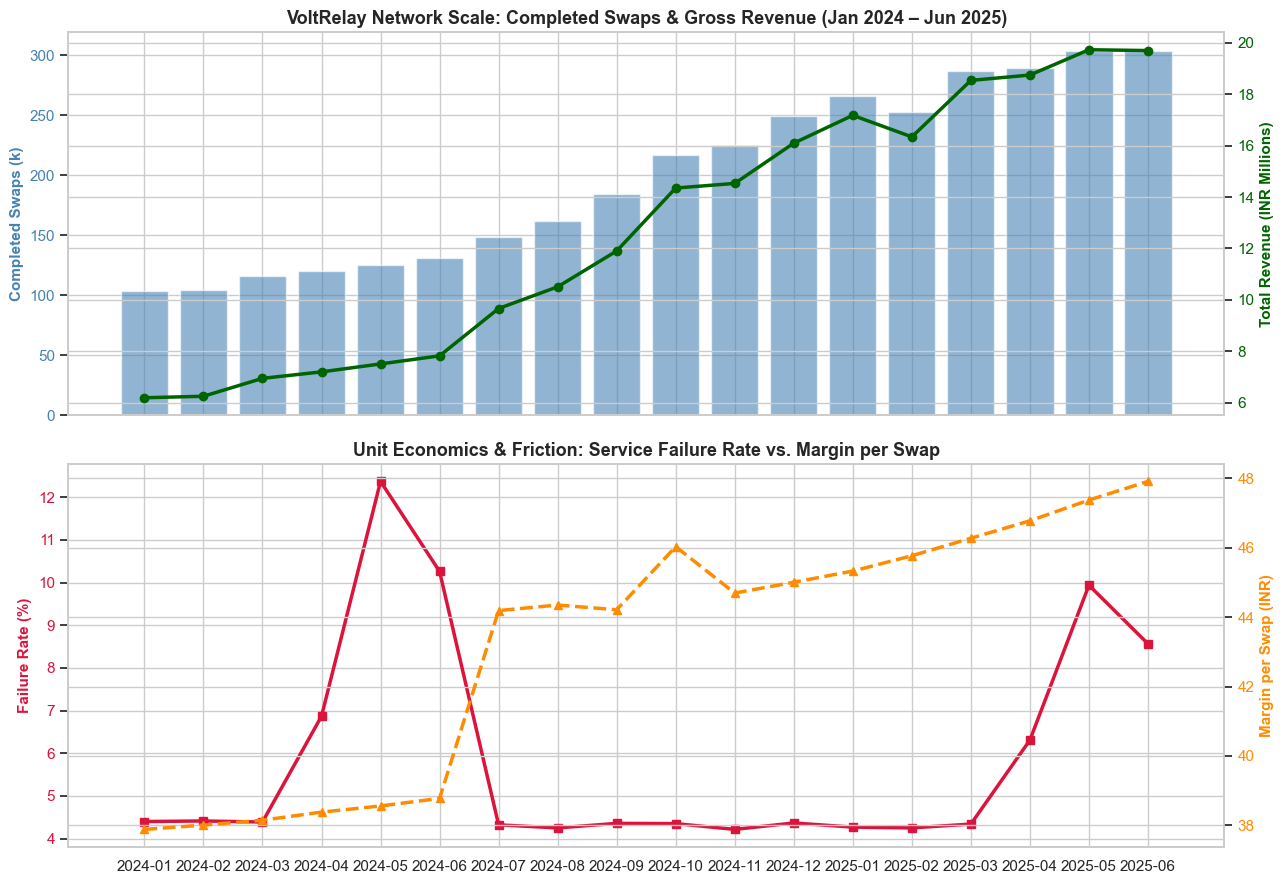

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df_swaps = pd.read_csv('Hackathon Data Set _ Gradient/swap_events.csv')
df_stations = pd.read_csv('Hackathon Data Set _ Gradient/stations.csv')


df_swaps = df_swaps[~df_swaps['station_id'].str.startswith('STN-TST', na=False)].copy()


df_swaps['event_ts'] = pd.to_datetime(df_swaps['event_ts'])
df_swaps = df_swaps.sort_values('event_ts')
offline_mask = df_swaps['sync_mode'] == 'offline_batch'
dups = df_swaps[offline_mask].duplicated(subset=['rider_id', 'station_id', 'battery_in_id', 'battery_out_id'], keep='first')
df_swaps = df_swaps.drop(df_swaps[offline_mask][dups].index)


fw_mask = (
    (df_swaps['station_firmware'] == 'v3.2.0') &
    (df_swaps['event_ts'] >= '2025-03-10') &
    (df_swaps['event_ts'] <= '2025-04-14 23:59:59')
)
df_swaps.loc[fw_mask, 'event_ts'] += pd.Timedelta(hours=5, minutes=30)


df_swaps = df_swaps.merge(df_stations[['station_id', 'grid_tariff_inr_kwh']], on='station_id', how='left')
df_swaps['energy_cost_inr'] = df_swaps['energy_to_recharge_kwh'] * df_swaps['grid_tariff_inr_kwh']
df_swaps['contribution_margin_inr'] = df_swaps['amount_charged_inr'] - df_swaps['energy_cost_inr']

df_swaps['year_month'] = df_swaps['event_ts'].dt.to_period('M').astype(str)
df_swaps['is_completed'] = (df_swaps['event_type'] == 'swap_completed').astype(int)


monthly_kpis = df_swaps.groupby('year_month').agg(
    total_attempts=('event_id', 'count'),
    completed_swaps=('is_completed', 'sum'),
    total_revenue_inr=('amount_charged_inr', 'sum'),
    total_margin_inr=('contribution_margin_inr', 'sum')
).reset_index()

monthly_kpis['failure_rate_pct'] = ((monthly_kpis['total_attempts'] - monthly_kpis['completed_swaps']) / monthly_kpis['total_attempts']) * 100
monthly_kpis['avg_rev_per_swap'] = monthly_kpis['total_revenue_inr'] / monthly_kpis['completed_swaps']
monthly_kpis['margin_per_swap_inr'] = monthly_kpis['total_margin_inr'] / monthly_kpis['completed_swaps']

display(monthly_kpis)


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
sns.set_theme(style="whitegrid")


color1 = 'steelblue'
ax1.bar(monthly_kpis['year_month'], monthly_kpis['completed_swaps'] / 1000, color=color1, alpha=0.6, label='Completed Swaps (Thousands)')
ax1.set_ylabel('Completed Swaps (k)', color=color1, fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color1)

ax1_twin = ax1.twinx()
color2 = 'darkgreen'
ax1_twin.plot(monthly_kpis['year_month'], monthly_kpis['total_revenue_inr'] / 1e6, color=color2, marker='o', linewidth=2.5, label='Total Revenue (INR Millions)')
ax1_twin.set_ylabel('Total Revenue (INR Millions)', color=color2, fontsize=11, fontweight='bold')
ax1_twin.tick_params(axis='y', labelcolor=color2)
ax1.set_title('VoltRelay Network Scale: Completed Swaps & Gross Revenue (Jan 2024 – Jun 2025)', fontsize=13, fontweight='bold')


color3 = 'crimson'
ax2.plot(monthly_kpis['year_month'], monthly_kpis['failure_rate_pct'], color=color3, marker='s', linewidth=2.5, label='Failure Rate (%)')
ax2.set_ylabel('Failure Rate (%)', color=color3, fontsize=11, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color3)

ax2_twin = ax2.twinx()
color4 = 'darkorange'
ax2_twin.plot(monthly_kpis['year_month'], monthly_kpis['margin_per_swap_inr'], color=color4, marker='^', linewidth=2.5, linestyle='--', label='Contribution Margin / Swap (INR)')
ax2_twin.set_ylabel('Margin per Swap (INR)', color=color4, fontsize=11, fontweight='bold')
ax2_twin.tick_params(axis='y', labelcolor=color4)
ax2.set_title('Unit Economics & Friction: Service Failure Rate vs. Margin per Swap', fontsize=13, fontweight='bold')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The insights found by these metrics:
1. From upper graph: Completed Swaps and Gross Revenue:
    (i) Positive: The increasing completed swap counts indicate high market demand
    (ii) Positive: Total gross revenue (green line) scales closely alongside completed swap volume, climbing from ~₹6.2 million in early 2024 to a peak of ~₹19.5–20 million by May/June 2025.
    (iii) The dips in and near 11-2024(November 2024) show event and seasonal affect on swap and gross revenue performance.

2. From lower graph: Service Failure Rate vs. Margin per swap
    (i) Massive Failure Spike from April 2024 to June 2024 - showing severe early operational friction or inventory stockouts during summer heatwaves or initial network scaling phases before new station deployment or inventory adjustments took effect.
    (ii) From 2025 slot and early failures - VoltRelay successfully averted massive failures by improving per-swap profitability due to base price adjustments, the peak/off-peak pricing pilot, or renegotiated partner contracts. But this increased service friction and failures, pointing to network congestion or battery shortages under heavy demand.


Problem 2: Service Failures and Customer Experience:
 How do queue wait time, failed attempts, and abandoned swaps relate to station, hour of day, season, and vehicle class? Is service quality spread evenly across the network, or concentrated somewhere specific?

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df_riders = pd.read_csv('Hackathon Data Set _ Gradient/riders.csv', usecols=['rider_id', 'vehicle_class', 'plan_type'])
df_stations = pd.read_csv('Hackathon Data Set _ Gradient/stations.csv', usecols=['station_id', 'city', 'location_type', 'charger_generation'])
df_city = pd.read_csv('Hackathon Data Set _ Gradient/city_daily_context.csv')
df_hourly = pd.read_csv('Hackathon Data Set _ Gradient/station_hourly_status.csv', usecols=['station_id', 'hour_start', 'charged_2w_min', 'charged_3w_min', 'packs_quarantined'])


df_swaps['event_ts'] = pd.to_datetime(df_swaps['event_ts'])
df_swaps['hour_of_day'] = df_swaps['event_ts'].dt.hour
df_swaps['month'] = df_swaps['event_ts'].dt.month
df_swaps['date'] = df_swaps['event_ts'].dt.date
df_swaps['hour_start'] = df_swaps['event_ts'].dt.floor('h')

df_city['date'] = pd.to_datetime(df_city['date']).dt.date
df_hourly['hour_start'] = pd.to_datetime(df_hourly['hour_start'])

# 3. Merge tables
df_cx = (
    df_swaps
    .merge(df_riders, on='rider_id', how='left')
    .merge(df_stations, on='station_id', how='left')
    .merge(df_city, on=['city', 'date'], how='left')
    .merge(df_hourly, on=['station_id', 'hour_start'], how='left')
)

# 4. Create helper flags for failure types
df_cx['is_failed'] = (df_cx['event_type'] != 'swap_completed').astype(int)
df_cx['is_stockout'] = (df_cx['event_type'] == 'failed_no_charged_battery').astype(int)
df_cx['is_abandoned'] = (df_cx['event_type'] == 'abandoned_queue').astype(int)
df_cx['queue_wait_min'] = df_cx['queue_wait_sec'] / 60.0

print("Unified Customer Experience dataset ready:", df_cx.shape)

Unified Customer Experience dataset ready: (3814032, 53)


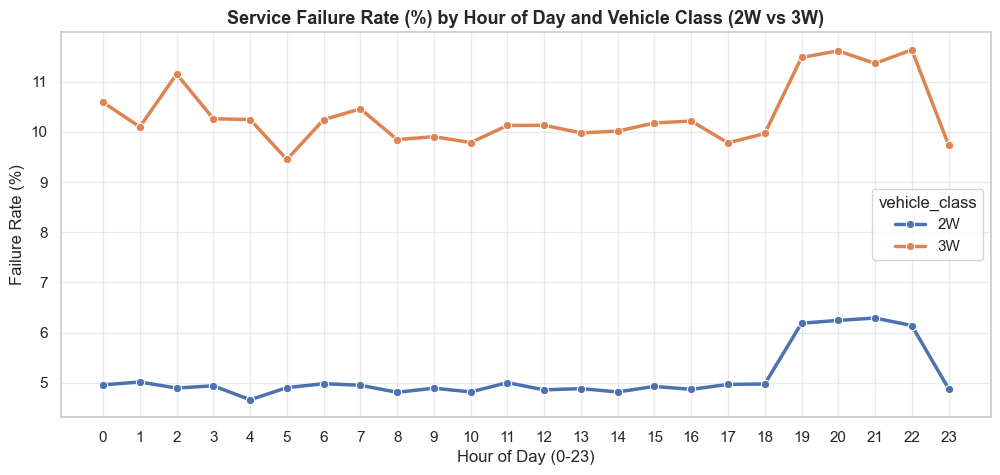


Weather Impact on Customer Experience


,heat_alert,flood_disruption,attempts,failure_rate_pct,stockout_rate_pct,avg_wait_min,avg_quarantined
0,False,False,3620776,5.492800,3.161035,4.049910,0.001060
1,False,True,3072,4.427083,2.441406,4.048177,0.000000
2,True,False,190184,14.903988,9.588609,4.050691,0.007433



Time for which riders wait in queue (in minutes)


event_type,abandoned_queue,cancelled_by_rider,failed_no_charged_battery,failed_system_error,swap_completed
count,67651.000000,15899.000000,132765.000000,11048.000000,3.586669e+06
mean,11.713172,0.743805,0.491620,0.741149,4.061969e+00
median,10.800000,0.750000,0.500000,0.733333,3.483333e+00
p90_wait_min,18.133333,1.350000,0.883333,1.333333,7.066667e+00


In [86]:
hourly_cx = df_cx.groupby(['hour_of_day', 'vehicle_class']).agg(
    total_attempts=('event_id', 'count'),
    failure_rate_pct=('is_failed', lambda x: x.mean() * 100),
    stockout_rate_pct=('is_stockout', lambda x: x.mean() * 100),
    abandoned_rate_pct=('is_abandoned', lambda x: x.mean() * 100),
    avg_wait_min=('queue_wait_min', 'mean')
).reset_index()

# Plot Failure Rate by Hour of Day split by Vehicle Class
plt.figure(figsize=(12, 5))
sns.lineplot(data=hourly_cx, x='hour_of_day', y='failure_rate_pct', hue='vehicle_class', marker='o', linewidth=2.5)
plt.title('Service Failure Rate (%) by Hour of Day and Vehicle Class (2W vs 3W)', fontsize=13, fontweight='bold')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Failure Rate (%)')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.4)
plt.show()

weather_cx = df_cx.groupby(['heat_alert', 'flood_disruption']).agg(
    attempts=('event_id', 'count'),
    failure_rate_pct=('is_failed', lambda x: x.mean() * 100),
    stockout_rate_pct=('is_stockout', lambda x: x.mean() * 100),
    avg_wait_min=('queue_wait_min', 'mean'),
    avg_quarantined=('packs_quarantined', 'mean')
).reset_index()
print()
print("Weather Impact on Customer Experience", end='\n')
display(weather_cx)

wait_by_outcome = df_cx.groupby('event_type')['queue_wait_min'].agg(['count', 'mean', 'median', lambda x: np.percentile(x.dropna(), 90)]).rename(columns={'<lambda_0>': 'p90_wait_min'})
print()
print("Time for which riders wait in queue (in minutes)",end='\n')
display(wait_by_outcome.T)

From above outputs, following insights can be extracted: 

1. Heatwaves Are the Primary Weather Driver of Service Failures:

    (i) Normal Weather (heat_alert = False, flood_disruption = False): Failure rate is 5.49%, and stockouts (stockout_rate_pct) are 3.16%.

    (ii) Heatwave Conditions (heat_alert = True): The overall failure rate nearly triples to 14.90%, driven almost entirely by stockouts jumping to 9.59%. Meanwhile, average quarantined packs (avg_quarantined) increase roughly 7x (from 0.00106 to 0.00743), confirming that thermal throttling and heat-induced battery quarantines directly starve stations of charged stock.

    (iii) Flood Disruptions (flood_disruption = True): Surprisingly, failure and stockout rates actually dip slightly to 4.43% and 2.44% (across 3,072 attempts). During floods, fewer riders are on the road, which reduces station congestion and prevents battery stockouts.

2. Severe vehicle assyemetry in 2 wheeler(2W) and 3 wheeler(3W):

    (i) 3W Failure Rate Is Double 2W All Day: Three-wheelers (orange line) suffer a baseline failure rate of 9.5% to 11.6% throughout the entire 24-hour cycle, compared to 4.7% to 6.3% for two-wheelers (blue line). Because 3W packs are larger (4.8 kWh) and stations have fewer 3W charging slots, 3W capacity is structurally undersupplied across the network.

    (ii)Evening Rush Spike (19:00 – 22:00): Both vehicle classes experience their worst service failures between 7:00 PM and 10:00 PM (peaking at ~11.6% for 3W and ~6.3% for 2W), reflecting peak dinner delivery and end-of-shift swap demand depleting station inventory. 

    (iii)Late-Night 3W Anomaly (00:00 – 02:00): Notice the sharp bump in 3W failures around 2:00 AM (~11.2%)—likely driven by overnight cargo/e-commerce logistics fleets swapping between shifts when stations have fewer active charging cycles or lower stock.


Problem 3: Station and Geographic Patterns:
 Stations differ in charger generation, location type, and when they were commissioned, and are not evenly distributed across cities. How do these differences relate to service performance, battery turnaround time, or customer complaints?

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df_stations = pd.read_csv('Hackathon Data Set _ Gradient/stations.csv')
df_stations = df_stations[~df_stations['station_id'].str.startswith('STN-TST', na=False)].copy()
df_stations['total_slots'] = df_stations['slots_2w'] + df_stations['slots_3w']

df_hourly = pd.read_csv('Hackathon Data Set _ Gradient/station_hourly_status.csv')
df_tickets = pd.read_csv('Hackathon Data Set _ Gradient/support_tickets.csv')


df_swaps['is_completed'] = (df_swaps['event_type'] == 'swap_completed').astype(int)
df_swaps['is_stockout'] = (df_swaps['event_type'] == 'failed_no_charged_battery').astype(int)

stn_swaps = df_swaps.groupby('station_id').agg(
    total_attempts=('event_id', 'count'),
    completed_swaps=('is_completed', 'sum'),
    stockouts=('is_stockout', 'sum'),
    avg_wait_min=('queue_wait_sec', lambda x: x.mean() / 60.0)
).reset_index()

stn_swaps['failure_rate_pct'] = ((stn_swaps['total_attempts'] - stn_swaps['completed_swaps']) / stn_swaps['total_attempts']) * 100
stn_swaps['stockout_rate_pct'] = (stn_swaps['stockouts'] / stn_swaps['total_attempts']) * 100


valid_hourly = df_hourly[df_hourly['telemetry_status'] != 'missing']
stn_telemetry = valid_hourly.groupby('station_id').agg(
    avg_charge_min=('avg_charge_minutes', 'mean'),
    total_quarantined=('packs_quarantined', 'sum'),
    total_outage_hrs=('outage_minutes', lambda x: x.sum() / 60.0)
).reset_index()

stn_tickets = df_tickets.dropna(subset=['station_id']).groupby('station_id').agg(
    ticket_count=('ticket_id', 'count')
).reset_index()

df_stn_master = (
    df_stations
    .merge(stn_swaps, on='station_id', how='left')
    .merge(stn_telemetry, on='station_id', how='left')
    .merge(stn_tickets, on='station_id', how='left')
)

df_stn_master['ticket_count'] = df_stn_master['ticket_count'].fillna(0)
df_stn_master['swaps_per_slot'] = df_stn_master['completed_swaps'] / df_stn_master['total_slots']
df_stn_master['tickets_per_1k_attempts'] = (df_stn_master['ticket_count'] / df_stn_master['total_attempts']) * 1000


for dim in ['charger_generation', 'expansion_wave', 'city', 'location_type', 'host_type']:
    print(f"\n--- Performance by {dim.upper()} ---")
    summary = df_stn_master.groupby(dim).agg(
        stations=('station_id', 'count'),
        avg_swaps_per_slot=('swaps_per_slot', 'mean'),
        avg_failure_pct=('failure_rate_pct', 'mean'),
        avg_stockout_pct=('stockout_rate_pct', 'mean'),
        avg_charge_min=('avg_charge_min', 'mean'),
        tickets_per_1k=('tickets_per_1k_attempts', 'mean')
    ).round(2)
    display(summary)


--- Performance by CHARGER_GENERATION ---


,stations,avg_swaps_per_slot,avg_failure_pct,avg_stockout_pct,avg_charge_min,tickets_per_1k
charger_generation,,,,,,
Gen1,51,2278.15,7.15,4.30,91.81,11.66
Gen2,62,1933.65,4.85,2.71,64.25,9.82
Gen3,37,790.24,4.87,2.72,42.15,12.03



--- Performance by EXPANSION_WAVE ---


,stations,avg_swaps_per_slot,avg_failure_pct,avg_stockout_pct,avg_charge_min,tickets_per_1k
expansion_wave,,,,,,
Launch,90,2337.28,6.12,3.59,79.84,10.44
Wave1_2024H2,30,1159.96,4.89,2.75,59.16,11.28
Wave2_2025H1,30,671.86,4.95,2.77,42.17,12.34



--- Performance by CITY ---


,stations,avg_swaps_per_slot,avg_failure_pct,avg_stockout_pct,avg_charge_min,tickets_per_1k
city,,,,,,
Bengaluru,32,1844.93,4.53,2.49,66.08,9.11
Delhi NCR,30,1874.36,6.81,4.07,72.18,13.04
Hyderabad,26,1820.28,6.24,3.65,71.83,12.32
Jaipur,18,1873.46,7.13,4.29,75.20,13.27
Mumbai,22,1621.58,4.42,2.42,61.21,8.91
Pune,22,1514.44,4.95,2.78,62.64,9.59



--- Performance by LOCATION_TYPE ---


,stations,avg_swaps_per_slot,avg_failure_pct,avg_stockout_pct,avg_charge_min,tickets_per_1k
location_type,,,,,,
commercial_hub,44,2440.14,5.96,3.49,76.64,10.78
highway_fuel_pump,21,1165.95,5.05,2.89,57.02,11.77
market,47,1762.26,5.85,3.39,68.36,11.00
residential,21,1407.79,5.22,2.97,62.03,10.88
tech_park,7,1533.34,5.23,2.99,72.19,9.79
transit_hub,10,1033.60,5.63,3.16,63.54,11.28



--- Performance by HOST_TYPE ---


,stations,avg_swaps_per_slot,avg_failure_pct,avg_stockout_pct,avg_charge_min,tickets_per_1k
host_type,,,,,,
fuel_retailer,31,1678.18,5.61,3.24,69.79,10.99
kirana,38,1903.95,5.64,3.25,65.91,10.91
mall_parking,44,1772.33,5.63,3.24,68.20,11.04
owned_lot,37,1701.46,5.68,3.28,69.10,11.02


Testing whether expansion waves relieved launch stations

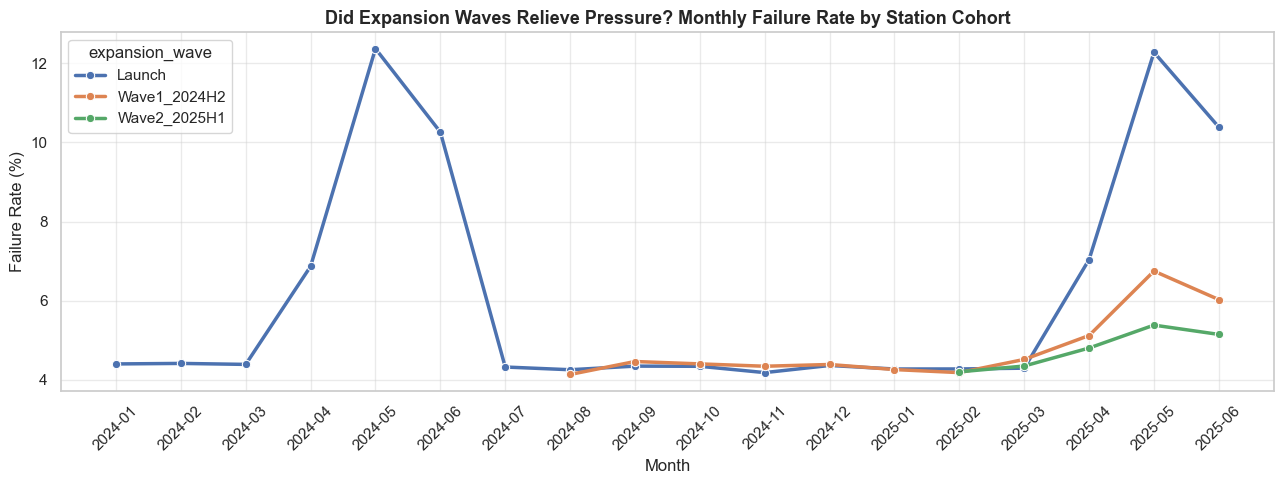

In [88]:

df_swaps_wave = df_swaps.merge(df_stations[['station_id', 'expansion_wave', 'city']], on='station_id', how='inner')
df_swaps_wave['year_month'] = pd.to_datetime(df_swaps_wave['event_ts']).dt.to_period('M').astype(str)
df_swaps_wave['is_failed'] = (df_swaps_wave['event_type'] != 'swap_completed').astype(int)

wave_trends = df_swaps_wave.groupby(['year_month', 'expansion_wave']).agg(
    completed_swaps=('is_completed', 'sum'),
    failure_rate_pct=('is_failed', lambda x: x.mean() * 100)
).reset_index()


plt.figure(figsize=(13, 5))
sns.lineplot(data=wave_trends, x='year_month', y='failure_rate_pct', hue='expansion_wave', marker='o', linewidth=2.5)
plt.title('Did Expansion Waves Relieve Pressure? Monthly Failure Rate by Station Cohort', fontsize=13, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Failure Rate (%)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

The insights from these data sets are:

1. Charger Generation Bottlenecks (Gen1 vs. Gen3):
    By the failure rates and average recharge times, it can be concluded that Gen1 Chargers are a liable option and Gen3 chargers solve the problem.
    But till current date, Gen1 chargers handle much of operations(2,278 swaps per slot) in dense utility regions and averaging a 7.15% failure rate and a slow 91.81-minute average charge duration. Newer Gen3 chargers cut average charge time almost in half (42.15 minutes) compared to Gen1, but currently handle lower swaps per slot (790) because they are predominantly installed in newer expansion waves.
    Key Takeaway: 
    Gen1 cabinets suffer from thermal bottlenecks and slow turnaround times, driving up stockouts (4.30%). Upgrading Gen1 sites to Gen3 should be a primary capital expenditure recommendation.

2. Expansion Wave Effectiveness:
    The line chart proves that 'Launch' stations carry extreme volatility. They experienced massive failure spikes of ~12.5% in May 2024 and ~12% in May 2025.In contrast, Wave1_2024H2 and Wave2_2025H1 maintained flat, controlled failure rates (~4% to 6%) even during the May 2025 network surge. Also while Launch stations average 2,337 swaps per slot and an 7.28% failure rate, Wave2_2025H1 stations average only 671 swaps per slot. 
    Key Takeaway:
    Expansion waves successfully avoided the high failure rates of early operations, but because newer stations were placed in lower-density areas, they failed to fully relieve traffic pressure on overcrowded legacy Launch stations, leaving core commercial hubs congested.

3. Geographic & City-Level Disparities (Delhi & Jaipur vs. Pune & Hyderabad):
    By comparing avg_swaps_per_slots and tickets_per_1k for heat-prone cities like Jaipur and Delhi against sea-side or coooler cities like Pune and Hyderabad:
        Jaipur (7.13% failure, 75.2 min charge time) and Delhi NCR (6.81% failure, 72.18 min charge time) are the most strained cities on the network and customer support tickets per 1,000 attempts (>13 tickets/1k). This is directly tied to severe ambient heat conditions in those regions.
        Mumbai (4.42% failure) and Bengaluru (4.53% failure) maintain smooth operations with lower charge times (~61–66 mins) and fewer support tickets (~8–9 per 1k).
    Key Takeaway:
    Hotter northern markets (Jaipur, Delhi) require aggressive cooling and inventory buffers compared to coastal/southern hubs.

4. Location Type vs. Host Type Dynamics:
    Commercial Hubs are Super-Highways: commercial_hub locations drive massive throughput, averaging 2,440 swaps per slot (the highest of any location type) and longer charge times (76.64 mins) due to constant queuing while performance across host_type (kirana, fuel_retailer, mall_parking, owned_lot) is remarkably uniform, with failure rates hovering around 5.6% across all host types.
    Key Takeaway: The physical micro-environment (location_type like commercial hubs) dictates congestion and load far more than who hosts the station (host_type).

Problem 4: Battery and Equipment Performance:
 How does battery health (state of health, charge cycles, supplier, manufacturing lot) relate to delivered range and swap frequency? Do any equipment or supplier cohorts stand out from the rest?

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_batteries = pd.read_csv('Hackathon Data Set _ Gradient/batteries.csv')
df_swaps = df_swaps[['event_id', 'battery_in_id', 'battery_out_id', 'km_since_last_swap', 'soh_in_pct', 'event_type']]


df_batteries['soh_drop_pct'] = df_batteries['initial_soh_pct'] - df_batteries['current_soh_pct']

battery_swaps = df_swaps[df_swaps['event_type'] == 'swap_completed'].groupby('battery_out_id').agg(
    total_swaps=('event_id', 'count')
).reset_index().rename(columns={'battery_out_id': 'battery_id'})


battery_range = df_swaps.groupby(['battery_in_id']).agg(
    avg_km_per_swap=('km_since_last_swap', 'mean'),
    avg_return_soc=('soh_in_pct', 'mean') 
).reset_index()
battery_range=battery_range.rename(columns={'battery_in_id': 'battery_id'})

df_battery_master_1 = (
    df_batteries
    .merge(battery_swaps, on='battery_id', how='left')
)
df_battery_master=(df_battery_master_1.merge(battery_range, on='battery_id', how='left'))

df_battery_master['total_swaps'] = df_battery_master['total_swaps'].fillna(0)


supplier_lot_summary = df_battery_master.groupby(['supplier', 'manufacturing_lot']).agg(
    battery_count=('battery_id', 'count'),
    avg_initial_soh=('initial_soh_pct', 'mean'),
    avg_current_soh=('current_soh_pct', 'mean'),
    avg_soh_drop=('soh_drop_pct', 'mean'),
    avg_total_swaps=('total_swaps', 'mean'),
    avg_delivered_km=('avg_km_per_swap', 'mean')
).reset_index().sort_values(by='avg_soh_drop', ascending=False)

print("Supplier & Manufacturing Lot Performance Summary:")
display(supplier_lot_summary.sort_values(by='avg_delivered_km', ascending=True))

Supplier & Manufacturing Lot Performance Summary:


,supplier,manufacturing_lot,battery_count,avg_initial_soh,avg_current_soh,avg_soh_drop,avg_total_swaps,avg_delivered_km
45,Kyron,KY-2409,481,99.205405,60.915177,38.290229,400.706861,50.306539
44,Kyron,KY-2408,500,99.218000,61.048400,38.169600,400.538000,50.858581
43,Kyron,KY-2407,480,99.170000,60.986042,38.183958,400.952083,50.864631
30,Cellora,CE-2405,127,99.171654,80.636220,18.535433,615.086614,64.084641
20,Cellora,CE-2307,143,99.187413,80.598601,18.588811,615.559441,64.253586
23,Cellora,CE-2310,117,99.169231,80.617094,18.552137,617.803419,64.329339
19,Cellora,CE-2306,122,99.209836,80.650000,18.559836,615.106557,64.416981
29,Cellora,CE-2404,158,99.140506,80.612658,18.527848,617.164557,64.426894
25,Cellora,CE-2312,137,99.222628,80.707299,18.515328,609.153285,64.607872
7,Amptek,AM-2410,81,99.159259,80.602469,18.556790,616.530864,64.635816


From above output we can determine:

1. Early Kyron Batteries (KY-2407 TO KY-2409) suffered high wear degradation and poor range output (50.3 to 50.8 km) but Later Kyron Batteries (post KY-2410) gave low wear degradation and high range(90km +). The newer range giving almost 2x more range output and were even greater than Cellora and Amptek.

2. Cellora and Amptek gave almost consistent degradation and range outputs across all battery ranges. They give an average range of 63-65km+ range and suffered degradation of about 12-18%.

Key takeaways:

(i) Older Kyron batteries(KY-2407, KY-2408 & KY-2409) should be decommisioned for vehicular usage.

(ii) Consistent battery manufactureres namely Cellora and Amptek should be continued as partners and future supplies.

(iii) The cell chemistry should be audited for Kyron Battery manufacturers to avoid low output or bad che,istry based cells in market.

Problem 5: Pricing and Partner Economics: 
How do the base price change, the peak/off-peak pricing pilot, and individual fleet partner contract terms relate to swap timing, revenue, and contribution margin? Do they affect every rider segment the same way?

In [90]:
import pandas as pd
import numpy as np


df_swaps = pd.read_csv('Hackathon Data Set _ Gradient/swap_events.csv', usecols=['event_id', 'rider_id', 'station_id', 'event_type', 'tariff_code', 'amount_charged_inr', 'energy_to_recharge_kwh'])
df_riders = pd.read_csv('Hackathon Data Set _ Gradient/riders.csv', usecols=['rider_id', 'partner_id', 'plan_type', 'vehicle_class'])
df_partners = pd.read_csv('Hackathon Data Set _ Gradient/fleet_partners.csv')
df_stations = pd.read_csv('Hackathon Data Set _ Gradient/stations.csv', usecols=['station_id', 'grid_tariff_inr_kwh'])


df_swaps = df_swaps[df_swaps['event_type'] == 'swap_completed'].copy()
df_swaps = df_swaps[~df_swaps['station_id'].str.startswith('STN-TST', na=False)]

df_pricing = (
    df_swaps
    .merge(df_riders, on='rider_id', how='left')
    .merge(df_stations, on='station_id', how='left')
    .merge(df_partners, on='partner_id', how='left', suffixes=('', '_partner'))
)


df_pricing['energy_cost_inr'] = df_pricing['energy_to_recharge_kwh'] * df_pricing['grid_tariff_inr_kwh']
df_pricing['contribution_margin_inr'] = df_pricing['amount_charged_inr'] - df_pricing['energy_cost_inr']


df_pricing['partner_name'] = df_pricing['partner_name'].fillna('Independent / Retail')


partner_economics = df_pricing.groupby(['partner_name', 'plan_type']).agg(
    total_completed_swaps=('event_id', 'count'),
    total_revenue_inr=('amount_charged_inr', 'sum'),
    total_margin_inr=('contribution_margin_inr', 'sum'),
    avg_margin_per_swap=('contribution_margin_inr', 'mean')
).sort_values(by='total_margin_inr', ascending=False).reset_index()

print("Fleet Partner & Segment Contribution Margin Summary:")
display(partner_economics)

Fleet Partner & Segment Contribution Margin Summary:


,partner_name,plan_type,total_completed_swaps,total_revenue_inr,total_margin_inr,avg_margin_per_swap
0,Independent / Retail,pay_as_you_go,846438,57756019.00,4.237063e+07,50.057565
1,FeastFly,partner_billed,516367,32027884.50,2.262417e+07,43.814128
2,Independent / Retail,prepaid_pack,372083,25359502.00,1.860606e+07,50.005137
3,ZipDrop,partner_billed,549390,28606514.80,1.809065e+07,32.928618
4,ParcelNest,partner_billed,296209,16740212.75,1.136987e+07,38.384604
5,Swiggle Go,partner_billed,237632,14092428.90,9.728658e+06,40.940016
6,CargoTuk,partner_billed,131334,13062630.80,7.704624e+06,58.664352
7,QuickCart,partner_billed,127961,7934508.55,5.645873e+06,44.121826
8,RideMitra,partner_billed,119503,7494595.50,5.351016e+06,44.777254
9,DabbaXpress,partner_billed,92027,5853723.60,4.191878e+06,45.550527


This data gives following insights:

1. Independent /Retail partners in both billed and prepaid packs provide the highest swaps (pay_as_you_go with 846,438 swaps and prepaid_pack with 372,083 swaps) and highest margin_per_swap profitability (₹50.00 to ₹50.05 per swap) for VoltRelay.

2. For B2B partners, ZipDrop sits at the highest swap count of 549390 among all B2B partners.
   But, it can be observed that even with this count the average margin_per_swap is the lowest in the entire network at ₹32.93. This shows that downside of improper discount provision.

3. HaulKing (₹59.59 avg margin) and CargoTuk (₹58.66 avg margin) achieve by far the highest average margins per swap in the network, well above the retail baseline.
   Strategic takeaway:Even with higher energy requirements (likely 3W cargo fleets), these partners operate on commercial pricing structures or bulk pack tariffs that generate superior returns per transaction despite lower absolute swap volumes (53k and 131k swaps respectively).

4. Partners like FeastFly, QuickCart, and DabbaXpress form a stable mid-tier group. Their average margins hover predictably in the mid-to-high ₹40s, indicating standard B2B contract terms with moderate discounting.

Key Takeaways:

(i) VoltRelay should renegotiate and tighten discount structures with ZipDrop to increase possible profit margin.

(ii) Volt Relay should raise focus on acquiring and expanding 3W cargo fleet partners like HaulKing and CargoTuk, as they deliver exceptional unit margins that maximize profitability per station slot.

Problem 6: Root Cause Analysis of Retention:
 Identify the most important factors associated with new riders not returning to the platform. Use evidence to distinguish between factors that appear to be primary drivers and factors that appear to be secondary or contributing. You are not expected to prove a single cause; more than one factor likely contributes.

Root Cause Analysis: Churned (0) vs. Retained (1)


,is_retained,rider_count,avg_week1_attempts,avg_week1_stockouts,avg_week1_wait_min,avg_week1_tickets,avg_resolution_hrs
0,0,7925,5.290726,0.194700,2.910896,0.054511,17.024100
1,1,12075,6.703685,0.234369,3.556323,0.072133,16.146785


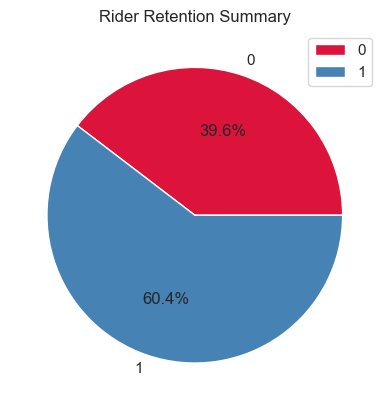

In [91]:
import pandas as pd
import numpy as np

df_swaps = pd.read_csv('Hackathon Data Set _ Gradient/swap_events.csv', usecols=['event_id', 'rider_id', 'event_type', 'event_ts', 'queue_wait_sec'])
df_riders=pd.read_csv('Hackathon Data Set _ Gradient/riders.csv')
df_riders['signup_date'] = pd.to_datetime(df_riders['signup_date'])
df_swaps['event_ts'] = pd.to_datetime(df_swaps['event_ts'])
cutoff_date = pd.to_datetime('2025-06-30')


last_swap = df_swaps[df_swaps['event_type'] == 'swap_completed'].groupby('rider_id')['event_ts'].max().reset_index()
last_swap.rename(columns={'event_ts': 'last_swap_date'}, inplace=True)
df_riders = df_riders.merge(last_swap, on='rider_id', how='left')


churn_threshold_date = cutoff_date - pd.Timedelta(days=30)
df_riders['is_retained'] = (df_riders['last_swap_date'] >= churn_threshold_date).astype(int)


df_onboarding = df_swaps.merge(df_riders[['rider_id', 'signup_date']], on='rider_id', how='inner')
df_onboarding['days_since_signup'] = (df_onboarding['event_ts'] - df_onboarding['signup_date']).dt.days

week1_swaps = df_onboarding[(df_onboarding['days_since_signup'] >= 0) & (df_onboarding['days_since_signup'] <= 7)]

week1_friction = week1_swaps.groupby('rider_id').agg(
    week1_attempts=('event_id', 'count'),
    week1_stockouts=('event_type', lambda x: (x == 'failed_no_charged_battery').sum()),
    week1_avg_wait_sec=('queue_wait_sec', 'mean')
).reset_index()


df_tickets['created_ts'] = pd.to_datetime(df_tickets['created_ts'])
ticket_summary = df_tickets.merge(df_riders[['rider_id', 'signup_date']], on='rider_id', how='inner')
ticket_summary['ticket_days_since_signup'] = (ticket_summary['created_ts'] - ticket_summary['signup_date']).dt.days

week1_tickets = ticket_summary[(ticket_summary['ticket_days_since_signup'] >= 0) & (ticket_summary['ticket_days_since_signup'] <= 7)]

ticket_metrics = week1_tickets.groupby('rider_id').agg(
    week1_ticket_count=('ticket_id', 'count'),
    avg_resolution_hours=('resolution_hours', 'mean')
).reset_index()


master_retention = (
    df_riders[['rider_id', 'plan_type', 'signup_channel', 'is_retained']]
    .merge(week1_friction, on='rider_id', how='left')
    .merge(ticket_metrics, on='rider_id', how='left')
)


master_retention['week1_attempts'] = master_retention['week1_attempts'].fillna(0)
master_retention['week1_stockouts'] = master_retention['week1_stockouts'].fillna(0)
master_retention['week1_avg_wait_sec'] = master_retention['week1_avg_wait_sec'].fillna(0)
master_retention['week1_ticket_count'] = master_retention['week1_ticket_count'].fillna(0)


retention_summary = master_retention.groupby('is_retained').agg(
    rider_count=('rider_id', 'count'),
    avg_week1_attempts=('week1_attempts', 'mean'),
    avg_week1_stockouts=('week1_stockouts', 'mean'),
    avg_week1_wait_min=('week1_avg_wait_sec', lambda x: x.mean() / 60.0),
    avg_week1_tickets=('week1_ticket_count', 'mean'),
    avg_resolution_hrs=('avg_resolution_hours', 'mean')
).reset_index()

print("Root Cause Analysis: Churned (0) vs. Retained (1)")
display(retention_summary)


plt.pie(retention_summary['rider_count'],labels=retention_summary['is_retained'],autopct='%.1f%%',colors=['crimson','steelblue'])
plt.title("Rider Retention Summary")
plt.legend({0:'Churned', 1:'Retained'})
plt.show()


The following insights can be driven from above data:

1. Out of the analyzed cohort, 60.4% (12,075 riders) were successfully retained, while 39.6% (7,925 riders) churned. A ~40% churn rate highlights a substantial retention leak during or immediately following the onboarding window

2. Retained riders logged a higher average number of week-1 attempts (5.67) compared to churned riders (5.29).

3. Churned riders experienced fewer week-1 stockouts (0.19 vs. 0.23) and shorter average queue wait times (2.91 minutes vs. 3.56 minutes) than retained riders.

4. Retained riders filed slightly more support tickets in week 1 (0.07 vs. 0.05), while support resolution times remained nearly identical across both groups (~16 to 17 hours).

Key Takeaways:

(i) Retained riders care enough about resolving service issues to reach out to customer support, whereas churned riders often experience low engagement and quietly abandon the platform without troubleshooting.

(ii) The data shows that low initial adoption and passive usage are the true precursors to churn.

(iii)Resolution time is constant for both retained and churned riders (16-17 hours). Thus this margin should be reduced.

(iii)VoltRelay should focus onboarding campaigns on driving higher week-1 transaction frequency along with fixing isolated wait times.

Conclusion:

The findings from above analysis can be summarized as follows: 

1. VoltRelay relieved launch chargers from operational overhead to some extent by launching expansion waves Wave1_2024H1 and Wave2_2025H2

2. The expansion waves failed due to improper distribution of new chargers. New chargers were provided at less operational centric regions than the more friction prone regions. VoltRelay should should focus on providing multiple charging stations in heavy demand regions close-by to allow less friction and stockout cases.

3. The Kyron battery manufacturers should be audited for cell chemistry for preventing future issues such as low range. VoltRelay should maintain partnership with reliable battery manufacturers such as Amptek and Cellora for consistent battery performance and customer service.

4. Gen1 chargers are highly affected by heat conditions and take long charging time of 91.81-minute average while Gen3 chargers take around 42.15 minutes in average and show consistent performance in peak heat conditions.

5. The Gen1 chargers are still handling the major operational load since the Gen2 and Gen3 chargers are mainly comissioned in low demand regions. VoltRelay should work on replacing Gen1 chargers with Gen3 chargers for better service provision and better customer response.

6. The chargers in heat-prone states like DelhiNCR and Jaipur must be provided with aggressive cooling solutions to avoid service failures.

7. VoltRelay should renegotiate its price slabs and discounts with major B2B partners such as ZipDrop to facilitate increase in profits gained per swap.

8. VoltRelay should increase partnership with 3W cargo partners like HaulKing and CargoTuk for high profit margin with low swap counts.

9. The Root Causes for distruption in profit and less customer retention are: 

   (i) Lack of promotional initiatives to engage customers to try VoltRelay Swapping Stations.

   (ii) Service failures and customer friction during high demand due to slow Gen1 chargers in such regions along with less quantity of batteries to handle peak demands and long waiting times.

   (iii) Issue resolution takes about 16-17 hours which can lead to customer churning.

